# TSS → nearest TF binding site distance in *Drosophila melanogaster*

**Goal:** Compute the 1D genomic distance (in bp) between the transcription start site (TSS) of each gene and its nearest associated TF binding site (TFBS).

**Data sources:**
1. **NCBI RefSeq GFF** (`dm6 / Release 6`) — gene models → TSS positions  
2. **ORegAnno** (via UCSC `dm6` public MySQL) — curated TFBS with gene associations (originally from REDfly/FLYREG)

**Analysis:**
- Genome-wide histogram of TSS→nearest TFBS distance  
- Focused case study on the *hunchback* gene

In [15]:
import gzip, os, subprocess, json, re
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = '/home/tohme/.julia/dev/Droplet/data/flybase'
GFF_FILE = os.path.join(DATA_DIR, 'genomic.gff.gz')

In [9]:
"""
Count all feature types in the GFF to see what's available.
Also check for 'regulatory', 'enhancer', 'binding_site', 'promoter' features.
"""
from collections import Counter

feature_counts = Counter()
regulatory_examples = []

with gzip.open(GFF_FILE, 'rt') as f:
    for line in f:
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        if len(fields) < 9:
            continue
        ftype = fields[2]
        feature_counts[ftype] += 1
        
        # Save examples of potentially regulatory features
        if any(kw in ftype.lower() for kw in ['regulat', 'enhanc', 'bind', 'promot', 'silenc', 'insul']):
            if len(regulatory_examples) < 5:
                regulatory_examples.append(line.strip())

print("=== Feature type counts ===")
for ftype, count in feature_counts.most_common():
    print(f"  {ftype:35s} {count:>8d}")

print(f"\n=== Regulatory-like features found: {len(regulatory_examples)} ===")
for ex in regulatory_examples:
    print(f"  {ex[:150]}")

=== Feature type counts ===
  exon                                  190710
  CDS                                   163319
  mRNA                                   30802
  gene                                   17537
  mobile_genetic_element                  5734
  lnc_RNA                                 2374
  region                                  1870
  antisense_RNA                            621
  miRNA                                    485
  pseudogene                               339
  tRNA                                     317
  snoRNA                                   270
  primary_transcript                       266
  rRNA                                     134
  ncRNA                                     60
  snRNA                                     32
  SRP_RNA                                    2
  RNase_P_RNA                                2
  RNase_MRP_RNA                              1
  sequence_feature                           1

=== Regulatory-like features fo

In [ ]:
## 1. Extract TSS positions from NCBI RefSeq GFF

The TSS is the 5' end of the mRNA transcript:
- **+ strand genes**: TSS = `start` (leftmost coordinate)
- **– strand genes**: TSS = `end` (rightmost coordinate)

We need to map NCBI accession chromosomes (`NC_004354.4`, etc.) to UCSC-style names (`chrX`, `chr2L`, etc.) to match ORegAnno coordinates.

Additional regulation-related tables:

=== ORegAnno table structure ===
bin	smallint(5) unsigned	NO	MUL	NULL	
chrom	varchar(255)	NO		NULL	
chromStart	int(10) unsigned	NO		NULL	
chromEnd	int(10) unsigned	NO		NULL	
id	varchar(48)	NO	PRI	NULL	
strand	char(1)	NO		NULL	
name	varchar(255)	NO		NULL	

=== First 10 ORegAnno entries ===
585	chr2L	103818	103841	OREG0067323	+	OREG0067323
587	chr2L	281702	281723	OREG0067159	+	OREG0067159
587	chr2L	281826	281850	OREG0067161	+	OREG0067161
587	chr2L	281924	281948	OREG0068784	+	OREG0068784
588	chr2L	447473	447494	OREG0067967	+	OREG0067967
588	chr2L	447473	447494	OREG0067966	+	OREG0067966
588	chr2L	479642	479687	OREG0003023	-	OREG0003023
588	chr2L	479653	479665	OREG0002454	-	OREG0002454
588	chr2L	523293	523382	OREG0054314	+	OREG0054314
588	chr2L	523400	523407	OREG0054313	+	OREG0054313

=== ORegAnnoAttr structure ===
id	varchar(48)	NO	MUL	NULL	
attribute	varchar(48)	NO		NULL	
attrVal	varchar(255)	NO		NULL	

=== Sample attributes for first entry ===
OREG0

In [20]:
"""
Parse the NCBI GFF to extract:
- Gene name, chromosome, strand, TSS position
- Build accession→chromosome mapping from 'region' features
- TSS = start (+ strand) or end (- strand) of the gene
"""

# NCBI accession → UCSC chromosome name mapping for dm6
# Multiple accessions map to same chromosome (main + unplaced scaffolds)
# We only want the main chromosome assembly accessions
accession_to_chrom = {}
genes = []

with gzip.open(GFF_FILE, 'rt') as f:
    for line in f:
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        if len(fields) < 9:
            continue
        
        seqid, source, ftype, start, end, score, strand, phase, attributes = fields
        start, end = int(start), int(end)
        attrs = parse_attributes(attributes)
        
        # Build chromosome mapping from 'region' features with genome=chromosome
        if ftype == 'region' and attrs.get('genome') == 'chromosome':
            chrom_name = attrs.get('Name', '')
            if chrom_name:
                accession_to_chrom[seqid] = f'chr{chrom_name}'
        
        # Extract gene-level info
        if ftype == 'gene' and attrs.get('gene_biotype') == 'protein_coding':
            gene_name = attrs.get('gene', attrs.get('Name', 'unknown'))
            tss = start if strand == '+' else end
            
            genes.append({
                'seqid': seqid,
                'gene_name': gene_name,
                'strand': strand,
                'start': start,
                'end': end,
                'tss': tss,
                'gene_id': attrs.get('Dbxref', ''),
            })

# Apply chromosome mapping
for g in genes:
    g['chrom'] = accession_to_chrom.get(g['seqid'], g['seqid'])

genes_df = pd.DataFrame(genes)

# Keep only main chromosomes (chr2L, chr2R, chr3L, chr3R, chrX, chr4)
main_chroms = {'chr2L', 'chr2R', 'chr3L', 'chr3R', 'chrX', 'chr4'}
genes_df = genes_df[genes_df['chrom'].isin(main_chroms)].copy()

print(f"Accession → chromosome mapping: {accession_to_chrom}")
print(f"\nExtracted {len(genes_df)} protein-coding genes on main chromosomes")
print(f"\nChromosome distribution:")
print(genes_df['chrom'].value_counts().sort_index())
print(f"\nSample entries:")
genes_df.head(5)

Accession → chromosome mapping: {'NC_004354.4': 'chrX', 'NT_033779.5': 'chr2L', 'NT_033778.4': 'chr2R', 'NT_037436.4': 'chr3L', 'NT_033777.3': 'chr3R', 'NC_004353.4': 'chr4', 'NC_024512.1': 'chrY'}

Extracted 13925 protein-coding genes on main chromosomes

Chromosome distribution:
chrom
chr2L    2657
chr2R    2851
chr3L    2739
chr3R    3402
chr4       80
chrX     2196
Name: count, dtype: int64

Sample entries:


,seqid,gene_name,strand,start,end,tss,gene_id,chrom
0,NC_004354.4,CG17636,-,124370,126714,126714,"FLYBASE:FBgn0025837,GeneID:5740847",chrX
1,NC_004354.4,RhoGAP1A,+,127449,140340,127449,"FLYBASE:FBgn0025836,GeneID:5740235",chrX
2,NC_004354.4,tyn,+,140318,200663,140318,"FLYBASE:FBgn0284435,GeneID:3354987",chrX
3,NC_004354.4,CG17707,-,142731,148426,148426,"FLYBASE:FBgn0025835,GeneID:5740408",chrX
4,NC_004354.4,CG3038,-,243954,245856,245856,"FLYBASE:FBgn0040373,GeneID:30970",chrX


In [ ]:
## 2. Download ORegAnno TF binding sites from UCSC

ORegAnno contains curated regulatory elements from REDfly/FLYREG. Each entry has:
- Genomic coordinates (`chrom`, `chromStart`, `chromEnd`)
- Associated **gene** and **TF** (from the `oregannoAttr` table)
- Regulatory element type (TFBS, regulatory region, etc.)

SeqID: NC_004354.4, Name: X, chromosome=X
SeqID: NW_001845990.1, Name: X, chromosome=X
SeqID: NW_001846257.1, Name: X, chromosome=X
SeqID: NW_001845957.1, Name: X, chromosome=X
SeqID: NW_001845953.1, Name: X, chromosome=X
SeqID: NW_001845561.1, Name: X, chromosome=X
SeqID: NW_001846366.1, Name: X, chromosome=X
SeqID: NW_001845373.1, Name: X, chromosome=X
SeqID: NW_001845450.1, Name: X, chromosome=X
SeqID: NW_001845573.1, Name: X, chromosome=X


In [21]:
"""
Download all ORegAnno entries + attributes from UCSC public MySQL.
Join them to get TFBS with gene associations.
"""

# 1. Download all oreganno entries
result = subprocess.run(
    ['mysql', '-h', 'genome-mysql.soe.ucsc.edu', '-u', 'genome', '-D', 'dm6', '-N', '-A',
     '-e', "SELECT chrom, chromStart, chromEnd, id, strand FROM oreganno;"],
    capture_output=True, text=True, timeout=60
)

oreganno_rows = []
for line in result.stdout.strip().split('\n'):
    if line.strip():
        parts = line.split('\t')
        if len(parts) == 5:
            oreganno_rows.append({
                'chrom': parts[0],
                'chromStart': int(parts[1]),
                'chromEnd': int(parts[2]),
                'id': parts[3],
                'strand': parts[4],
            })

oreganno_df = pd.DataFrame(oreganno_rows)
print(f"Downloaded {len(oreganno_df)} ORegAnno entries")

# 2. Download all attributes
result2 = subprocess.run(
    ['mysql', '-h', 'genome-mysql.soe.ucsc.edu', '-u', 'genome', '-D', 'dm6', '-N', '-A',
     '-e', "SELECT id, attribute, attrVal FROM oregannoAttr;"],
    capture_output=True, text=True, timeout=60
)

attr_rows = []
for line in result2.stdout.strip().split('\n'):
    if line.strip():
        parts = line.split('\t')
        if len(parts) == 3:
            attr_rows.append({
                'id': parts[0],
                'attribute': parts[1],
                'attrVal': parts[2],
            })

attr_df = pd.DataFrame(attr_rows)
print(f"Downloaded {len(attr_df)} ORegAnno attributes")

# 3. Pivot attributes: each id gets columns for 'type', 'Gene', 'TFbs', 'Dataset'
attr_pivot = attr_df.pivot_table(index='id', columns='attribute', values='attrVal', 
                                  aggfunc='first').reset_index()
print(f"\nAttribute columns: {list(attr_pivot.columns)}")

# 4. Merge with coordinates
tfbs_df = oreganno_df.merge(attr_pivot, on='id', how='left')

# Show summary
print(f"\n=== Merged TFBS table: {len(tfbs_df)} entries ===")
print(f"\nType distribution:")
print(tfbs_df['type'].value_counts())
print(f"\nDataset distribution:")
print(tfbs_df['Dataset'].value_counts())
print(f"\nSample entries:")
tfbs_df.head()

Downloaded 4242 ORegAnno entries
Downloaded 15965 ORegAnno attributes

Attribute columns: ['id', 'Dataset', 'Gene', 'TFbs', 'type']

=== Merged TFBS table: 4242 entries ===

Type distribution:
type
Transcription Factor Binding Site    3466
Regulatory Region                     680
miRNA Binding Site                     96
Name: count, dtype: int64

Dataset distribution:
Dataset
REDfly        2695
FLYREG        1352
miRTarBase      96
Name: count, dtype: int64

Sample entries:


,chrom,chromStart,chromEnd,id,strand,Dataset,Gene,TFbs,type
0,chr2L,103818,103841,OREG0067323,+,miRTarBase,CG11377,dme-miR-1-3p,miRNA Binding Site
1,chr2L,281702,281723,OREG0067159,+,miRTarBase,smo,dme-miR-283-5p,miRNA Binding Site
2,chr2L,281826,281850,OREG0067161,+,miRTarBase,smo,dme-miR-12-5p,miRNA Binding Site
3,chr2L,281924,281948,OREG0068784,+,miRTarBase,smo,dme-miR-5-5p,miRNA Binding Site
4,chr2L,447473,447494,OREG0067967,+,miRTarBase,ex,dme-miR-278-3p,miRNA Binding Site


## 3. Compute TSS → TFBS distances

For each TFBS, compute the distance from the associated gene's TSS to the midpoint of the binding site. We use two approaches:

1. **Gene-associated distance**: Use the gene name from ORegAnno to look up the TSS in our gene table, then compute the genomic distance. This works even if the TFBS is far away (enhancers).
2. **Nearest-on-chromosome distance**: For each gene, find the nearest TFBS on the same chromosome (regardless of gene association).

In [22]:
"""
Approach 1: Gene-associated TFBS distances.
Match ORegAnno gene names → GFF gene names to get TSS, then compute distance.
"""

# Focus on TFBS and Regulatory Regions (exclude miRNA binding sites)
tfbs_only = tfbs_df[tfbs_df['type'].isin([
    'Transcription Factor Binding Site', 
    'Regulatory Region'
])].copy()
print(f"TFBS + Regulatory Region entries: {len(tfbs_only)}")

# Build gene name → TSS lookup (gene_name → {chrom, tss, strand})
# Some genes have multiple names; the GFF uses FlyBase gene symbols
gene_lookup = {}
for _, row in genes_df.iterrows():
    gene_lookup[row['gene_name']] = {
        'chrom': row['chrom'], 
        'tss': row['tss'], 
        'strand': row['strand']
    }

# Try to match ORegAnno gene names to our gene table
matched = 0
unmatched_genes = set()
distances = []

for _, row in tfbs_only.iterrows():
    gene_name = row['Gene']
    if gene_name in gene_lookup:
        gene_info = gene_lookup[gene_name]
        # TFBS midpoint
        tfbs_mid = (row['chromStart'] + row['chromEnd']) / 2
        
        # Check chromosomes match
        if gene_info['chrom'] == row['chrom']:
            dist = abs(gene_info['tss'] - tfbs_mid)
            
            # Signed distance: negative = upstream (5' of TSS), positive = downstream
            if gene_info['strand'] == '+':
                signed_dist = tfbs_mid - gene_info['tss']
            else:
                signed_dist = gene_info['tss'] - tfbs_mid
            
            distances.append({
                'gene': gene_name,
                'tf': row['TFbs'],
                'chrom': row['chrom'],
                'tss': gene_info['tss'],
                'tfbs_start': row['chromStart'],
                'tfbs_end': row['chromEnd'],
                'tfbs_mid': tfbs_mid,
                'distance': dist,
                'signed_distance': signed_dist,
                'type': row['type'],
                'dataset': row['Dataset'],
            })
            matched += 1
        else:
            unmatched_genes.add(gene_name)
    else:
        unmatched_genes.add(gene_name)

dist_df = pd.DataFrame(distances)
print(f"\nMatched {matched} TFBS entries to genes ({len(dist_df)} with distances)")
print(f"Unmatched gene names: {len(unmatched_genes)}")
print(f"Sample unmatched: {list(unmatched_genes)[:10]}")

# Per-gene: nearest TFBS distance
nearest_per_gene = dist_df.groupby('gene')['distance'].min().reset_index()
nearest_per_gene.columns = ['gene', 'nearest_tfbs_dist']
print(f"\nGenes with at least one matched TFBS: {len(nearest_per_gene)}")
print(f"\nNearest TFBS distance statistics (bp):")
print(nearest_per_gene['nearest_tfbs_dist'].describe())

TFBS + Regulatory Region entries: 4146

Matched 3831 TFBS entries to genes (3831 with distances)
Unmatched gene names: 46
Sample unmatched: ['Drs', 'h', 'His3', 'Sema-1b', 'HLHm7', 'Eip71CD', 'CG32150', 'Mes4', 'Deb-A', 'DNApol-alpha180']

Genes with at least one matched TFBS: 308

Nearest TFBS distance statistics (bp):
count       308.000000
mean       5344.355519
std       12630.361255
min           0.500000
25%          98.750000
50%         860.750000
75%        3229.375000
max      114841.500000
Name: nearest_tfbs_dist, dtype: float64


## 4. Genome-wide histogram: TSS → nearest TFBS distance

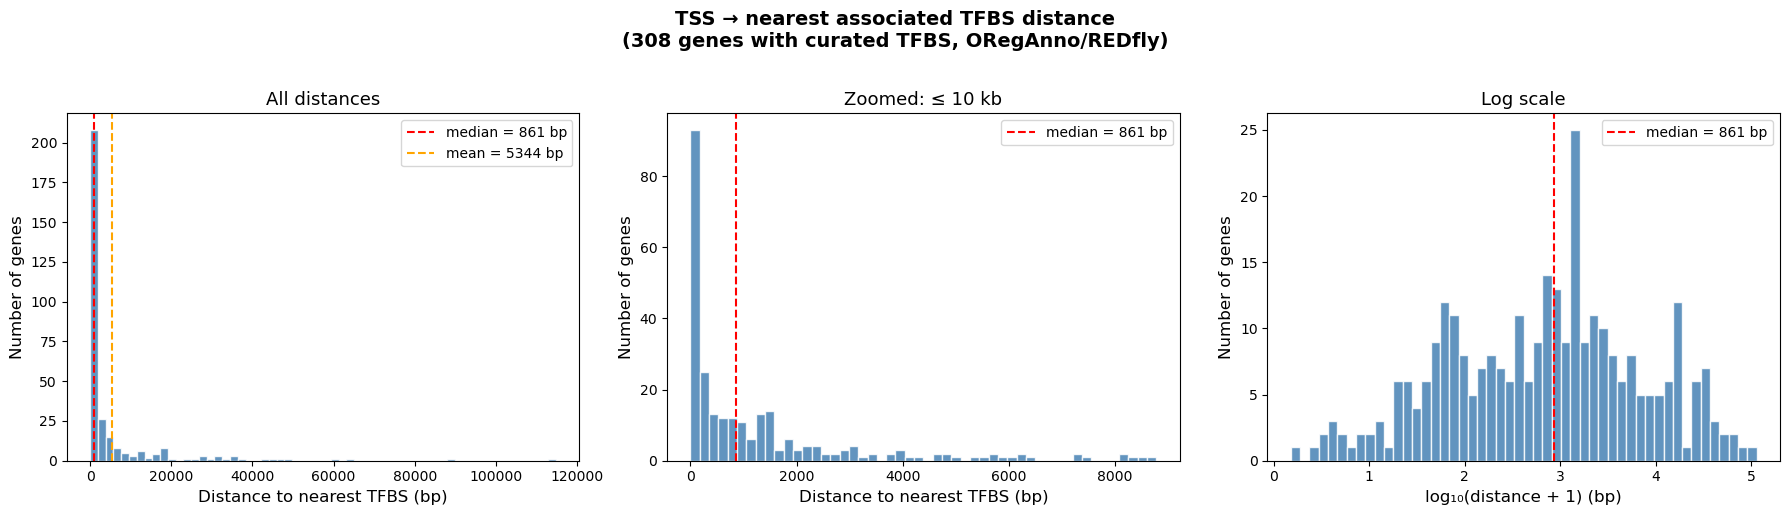


Summary: TSS → nearest TFBS distance (bp)
  N genes with TFBS data:  308
  Median:                  861 bp
  Mean:                    5344 bp
  25th percentile:         99 bp
  75th percentile:         3229 bp
  Min:                     0 bp
  Max:                     114842 bp
  Fraction ≤ 1 kb:         53.6%
  Fraction ≤ 5 kb:         79.5%
  Fraction ≤ 10 kb:        85.1%


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dists = nearest_per_gene['nearest_tfbs_dist'].values

# --- Panel 1: Full histogram ---
ax = axes[0]
ax.hist(dists, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(np.median(dists), color='red', ls='--', lw=1.5, label=f'median = {np.median(dists):.0f} bp')
ax.axvline(np.mean(dists), color='orange', ls='--', lw=1.5, label=f'mean = {np.mean(dists):.0f} bp')
ax.set_xlabel('Distance to nearest TFBS (bp)', fontsize=12)
ax.set_ylabel('Number of genes', fontsize=12)
ax.set_title('All distances', fontsize=13)
ax.legend(fontsize=10)

# --- Panel 2: Zoomed to ≤ 10 kb ---
ax = axes[1]
mask = dists <= 10000
ax.hist(dists[mask], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(np.median(dists), color='red', ls='--', lw=1.5, label=f'median = {np.median(dists):.0f} bp')
ax.set_xlabel('Distance to nearest TFBS (bp)', fontsize=12)
ax.set_ylabel('Number of genes', fontsize=12)
ax.set_title('Zoomed: ≤ 10 kb', fontsize=13)
ax.legend(fontsize=10)

# --- Panel 3: Log-scale ---
ax = axes[2]
ax.hist(np.log10(dists + 1), bins=50, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(np.log10(np.median(dists) + 1), color='red', ls='--', lw=1.5, 
           label=f'median = {np.median(dists):.0f} bp')
ax.set_xlabel('log₁₀(distance + 1) (bp)', fontsize=12)
ax.set_ylabel('Number of genes', fontsize=12)
ax.set_title('Log scale', fontsize=13)
ax.legend(fontsize=10)

fig.suptitle(f'TSS → nearest associated TFBS distance\n'
             f'({len(nearest_per_gene)} genes with curated TFBS, ORegAnno/REDfly)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'tss_tfbs_distance_histogram.png'), 
            dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
print(f"\n{'='*50}")
print(f"Summary: TSS → nearest TFBS distance (bp)")
print(f"{'='*50}")
print(f"  N genes with TFBS data:  {len(dists)}")
print(f"  Median:                  {np.median(dists):.0f} bp")
print(f"  Mean:                    {np.mean(dists):.0f} bp")
print(f"  25th percentile:         {np.percentile(dists, 25):.0f} bp")
print(f"  75th percentile:         {np.percentile(dists, 75):.0f} bp")
print(f"  Min:                     {np.min(dists):.0f} bp")
print(f"  Max:                     {np.max(dists):.0f} bp")
print(f"  Fraction ≤ 1 kb:         {np.mean(dists <= 1000):.1%}")
print(f"  Fraction ≤ 5 kb:         {np.mean(dists <= 5000):.1%}")
print(f"  Fraction ≤ 10 kb:        {np.mean(dists <= 10000):.1%}")

Fraction of TFBS upstream of TSS: 55.4%
Fraction of TFBS downstream of TSS: 44.6%
Median signed distance: -118 bp


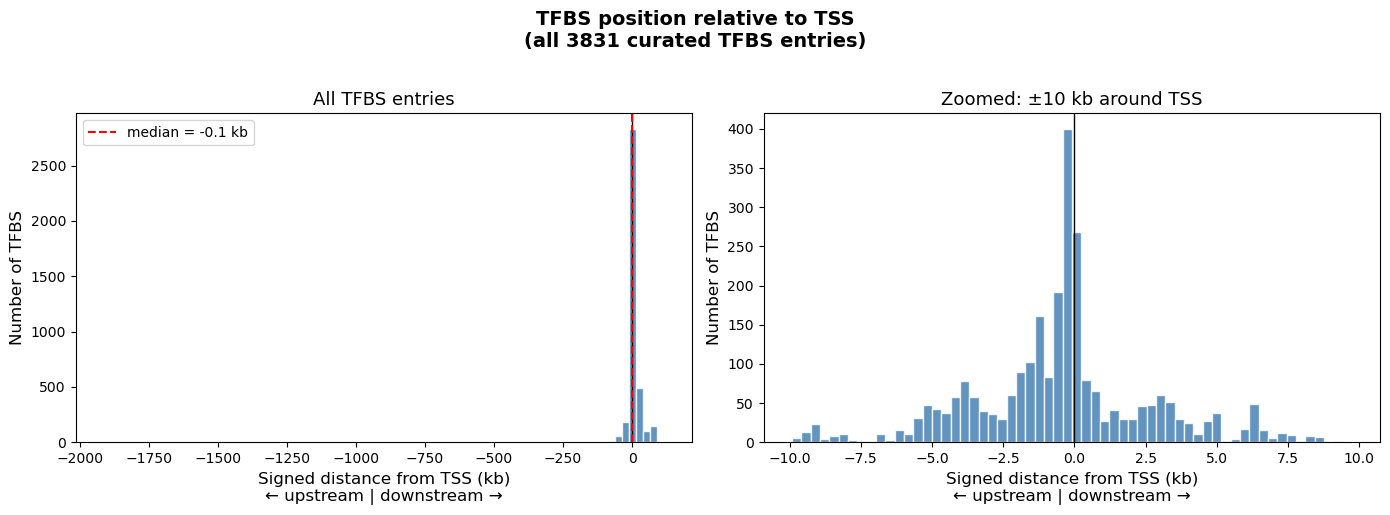

In [24]:
"""
Signed distance histogram: upstream (negative) vs downstream (positive) of TSS.
This shows whether TFBS tend to be upstream (in the promoter region) or downstream.
"""

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# All TFBS (not just nearest per gene)
signed = dist_df['signed_distance'].values

# --- Panel 1: All TFBS signed distances ---
ax = axes[0]
ax.hist(signed / 1000, bins=80, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(0, color='black', ls='-', lw=1)
ax.axvline(np.median(signed)/1000, color='red', ls='--', lw=1.5, 
           label=f'median = {np.median(signed)/1000:.1f} kb')
ax.set_xlabel('Signed distance from TSS (kb)\n← upstream | downstream →', fontsize=12)
ax.set_ylabel('Number of TFBS', fontsize=12)
ax.set_title('All TFBS entries', fontsize=13)
ax.legend(fontsize=10)

# --- Panel 2: Zoomed to ±10 kb ---
ax = axes[1]
mask = np.abs(signed) <= 10000
ax.hist(signed[mask] / 1000, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(0, color='black', ls='-', lw=1)
ax.set_xlabel('Signed distance from TSS (kb)\n← upstream | downstream →', fontsize=12)
ax.set_ylabel('Number of TFBS', fontsize=12)
ax.set_title('Zoomed: ±10 kb around TSS', fontsize=13)

# Fraction upstream vs downstream
frac_upstream = np.mean(signed < 0)
print(f"Fraction of TFBS upstream of TSS: {frac_upstream:.1%}")
print(f"Fraction of TFBS downstream of TSS: {1 - frac_upstream:.1%}")
print(f"Median signed distance: {np.median(signed):.0f} bp")

fig.suptitle(f'TFBS position relative to TSS\n(all {len(signed)} curated TFBS entries)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'tss_tfbs_signed_distance.png'), 
            dpi=150, bbox_inches='tight')
plt.show()

## 5. Case study: *hunchback* (*hb*)

Hunchback is a classic developmental gap gene with well-characterized regulation. It's regulated by Bicoid (activator) and by the posterior system. Let's examine all curated TFBS associated with *hb* and visualize their positions relative to the TSS.

In [25]:
"""
Hunchback case study: find all TFBS entries associated with hb.
The gene name in FlyBase is 'hb'.
"""

# Check what name hunchback has in our data
hb_candidates = [g for g in gene_lookup if 'hb' == g.lower() or 'hunchback' in g.lower()]
print(f"Hunchback gene name candidates: {hb_candidates}")

# Also check ORegAnno directly
hb_in_oreganno = tfbs_only[tfbs_only['Gene'].str.lower().isin(['hb', 'hunchback'])]
print(f"\nORegAnno entries for hb/hunchback: {len(hb_in_oreganno)}")

# Check in our distance table
hb_dists = dist_df[dist_df['gene'].str.lower().isin(['hb', 'hunchback'])]
print(f"Matched distance entries: {len(hb_dists)}")

if len(hb_dists) > 0:
    print(f"\nHunchback TSS: {hb_dists.iloc[0]['tss']} on {hb_dists.iloc[0]['chrom']}")
    print(f"\nAll TFBS for hb:")
    print(hb_dists[['tf', 'tfbs_start', 'tfbs_end', 'distance', 'signed_distance', 'type']].to_string())
else:
    # Try broader search
    print("\nTrying broader search in ORegAnno gene names...")
    for _, row in tfbs_only.iterrows():
        if 'hb' in row['Gene'].lower():
            print(f"  Gene: {row['Gene']}, TF: {row['TFbs']}, {row['chrom']}:{row['chromStart']}-{row['chromEnd']}")
    
    # Also check in gene_lookup
    hb_variants = [g for g in gene_lookup if 'hb' in g.lower()]
    print(f"\nGene names containing 'hb': {hb_variants[:20]}")

Hunchback gene name candidates: ['hb']

ORegAnno entries for hb/hunchback: 65
Matched distance entries: 65

Hunchback TSS: 8697822 on chr3R

All TFBS for hb:
       tf  tfbs_start  tfbs_end  distance  signed_distance                               type
2544  NaN     8694168   8694898    3289.0           3289.0                  Regulatory Region
2545  NaN     8694653   8694898    3046.5           3046.5                  Regulatory Region
2546  bcd     8694654   8694667    3161.5           3161.5  Transcription Factor Binding Site
2547  bcd     8694654   8694667    3161.5           3161.5  Transcription Factor Binding Site
2548  bcd     8694729   8694743    3086.0           3086.0  Transcription Factor Binding Site
2549  bcd     8694729   8694743    3086.0           3086.0  Transcription Factor Binding Site
2550  bcd     8694760   8694774    3055.0           3055.0  Transcription Factor Binding Site
2551  bcd     8694760   8694774    3055.0           3055.0  Transcription Factor Binding S

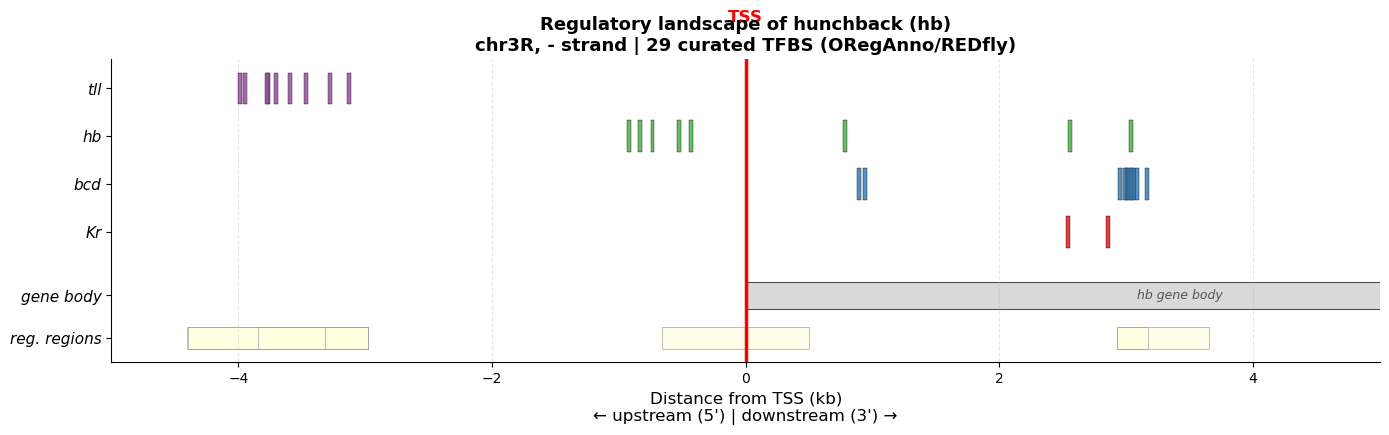


hunchback (hb) regulatory summary:
  TSS position: chr3R:8697822 (- strand)
  Gene body: 6,842 bp

  TFs binding near hb:
       Kr:  2 sites | nearest = 2,541 bp | range [+2.5, +2.9] kb from TSS
      bcd: 10 sites | nearest = 896 bp | range [+0.9, +3.2] kb from TSS
       hb:  8 sites | nearest = 430 bp | range [-0.9, +3.0] kb from TSS
      tll:  9 sites | nearest = 3,126 bp | range [-4.0, -3.1] kb from TSS


In [27]:
"""
Visualize hunchback regulatory landscape: all TFBS positions relative to TSS.
"""

# De-duplicate (many entries appear twice)
hb_unique = hb_dists.drop_duplicates(subset=['tf', 'tfbs_start', 'tfbs_end']).copy()
hb_unique['tf'] = hb_unique['tf'].fillna('unknown')

# Only TFBS (not regulatory regions without TF annotation)
hb_tfbs = hb_unique[hb_unique['type'] == 'Transcription Factor Binding Site'].copy()
hb_reg = hb_unique[hb_unique['type'] == 'Regulatory Region'].copy()

# Get unique TFs for color coding
tf_names = sorted([t for t in hb_tfbs['tf'].unique() if t != 'unknown'])
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
tf_colors = dict(zip(tf_names, colors[:len(tf_names)]))

fig, ax = plt.subplots(figsize=(14, 4.5))

# Gene body (relative to TSS = 0)
gene_row = genes_df[genes_df['gene_name'] == 'hb'].iloc[0]
gene_info = gene_lookup['hb']
gene_len = gene_row['end'] - gene_row['start']

# For minus-strand gene: TSS = end, so gene body extends in + direction (downstream)
# "downstream" = into the gene body = positive signed distance convention
if gene_info['strand'] == '-':
    gene_body_start = 0
    gene_body_end = gene_len
else:
    gene_body_start = 0  
    gene_body_end = gene_len

ax.barh(-0.3, gene_body_end/1000, left=gene_body_start/1000, 
        height=0.25, color='#d9d9d9', edgecolor='black', linewidth=0.5,
        label='gene body', zorder=1)
ax.text(gene_body_end/2000, -0.3, 'hb gene body', ha='center', va='center', 
        fontsize=9, fontstyle='italic', color='#555555')

# Plot regulatory regions as transparent bars
for _, row in hb_reg.iterrows():
    sd = row['signed_distance'] / 1000
    width = (row['tfbs_end'] - row['tfbs_start']) / 1000
    ax.barh(-0.7, width, left=sd - width/2, height=0.2,
            color='lightyellow', edgecolor='gray', linewidth=0.5, alpha=0.7, zorder=1)

# Plot TFBS grouped by TF
y_positions = {}
for i, tf in enumerate(tf_names):
    y_positions[tf] = 0.3 + i * 0.45

for _, row in hb_tfbs.iterrows():
    tf = row['tf']
    if tf == 'unknown':
        continue
    y = y_positions[tf]
    sd = row['signed_distance'] / 1000  # kb
    width = max((row['tfbs_end'] - row['tfbs_start']) / 1000, 0.03)  # min width for visibility
    
    ax.barh(y, width, left=sd - width/2, height=0.3, 
            color=tf_colors[tf], edgecolor='black', linewidth=0.3, alpha=0.85, zorder=2)

# TSS marker
ax.axvline(0, color='red', ls='-', lw=2.5, zorder=3)
ax.text(0, max(y_positions.values()) + 0.6, 'TSS', ha='center', va='bottom', 
        fontsize=12, color='red', fontweight='bold')

# Y-axis labels
all_y = [-0.7, -0.3] + [y_positions[tf] for tf in tf_names]
all_labels = ['reg. regions', 'gene body'] + tf_names
ax.set_yticks(all_y)
ax.set_yticklabels(all_labels, fontsize=11, fontstyle='italic')

# Axis styling
ax.set_xlabel('Distance from TSS (kb)\n← upstream (5\') | downstream (3\') →', fontsize=12)
ax.set_title(f'Regulatory landscape of hunchback (hb)\n'
             f'chr3R, {gene_info["strand"]} strand | '
             f'{len(hb_tfbs)} curated TFBS (ORegAnno/REDfly)', 
             fontsize=13, fontweight='bold')
ax.set_xlim(-5, 5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.3, ls='--')

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'hunchback_regulatory_landscape.png'), 
            dpi=150, bbox_inches='tight')
plt.show()

# Summary
print(f"\nhunchback (hb) regulatory summary:")
print(f"  TSS position: chr3R:{gene_info['tss']} ({gene_info['strand']} strand)")
print(f"  Gene body: {gene_len:,} bp")
print(f"\n  TFs binding near hb:")
for tf in tf_names:
    tf_entries = hb_tfbs[hb_tfbs['tf'] == tf]
    dists_tf = tf_entries['signed_distance'].values
    nearest = min(abs(dists_tf))
    print(f"    {tf:>5s}: {len(tf_entries):2d} sites | "
          f"nearest = {nearest:,.0f} bp | "
          f"range [{min(dists_tf)/1000:+.1f}, {max(dists_tf)/1000:+.1f}] kb from TSS")

## 6. Cumulative distribution & key numbers

The CDF makes it easy to read off "what fraction of genes have their nearest TFBS within $d$ bp of the TSS?"

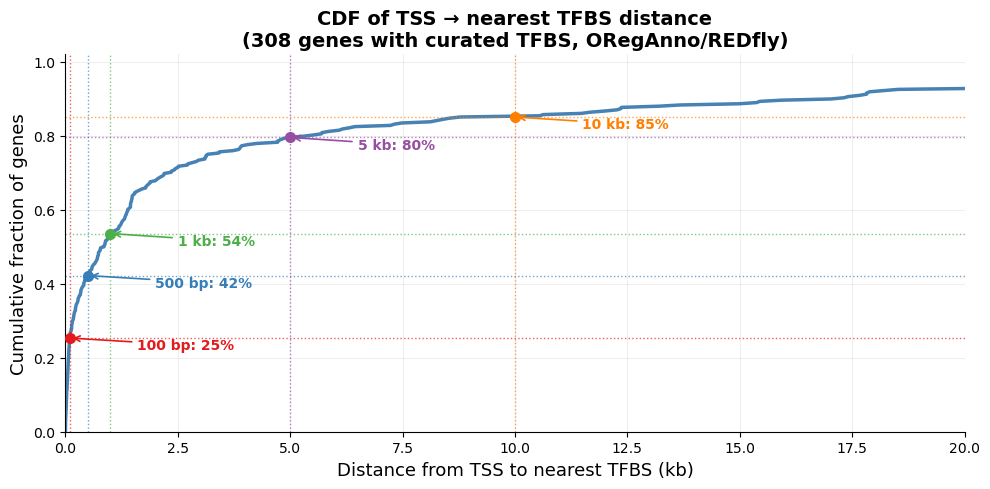

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))

dists_sorted = np.sort(dists)
cdf = np.arange(1, len(dists_sorted) + 1) / len(dists_sorted)

ax.plot(dists_sorted / 1000, cdf, color='steelblue', lw=2.5)
ax.set_xlabel('Distance from TSS to nearest TFBS (kb)', fontsize=13)
ax.set_ylabel('Cumulative fraction of genes', fontsize=13)
ax.set_title('CDF of TSS → nearest TFBS distance\n'
             f'({len(dists)} genes with curated TFBS, ORegAnno/REDfly)',
             fontsize=14, fontweight='bold')

# Annotate key thresholds
for threshold, color in [(100, '#e41a1c'), (500, '#377eb8'), (1000, '#4daf4a'), 
                          (5000, '#984ea3'), (10000, '#ff7f00')]:
    frac = np.mean(dists <= threshold)
    ax.axvline(threshold/1000, color=color, ls=':', lw=1, alpha=0.7)
    ax.axhline(frac, color=color, ls=':', lw=1, alpha=0.7)
    ax.plot(threshold/1000, frac, 'o', color=color, markersize=7, zorder=5)
    label = f'{threshold/1000:.0f} kb' if threshold >= 1000 else f'{threshold} bp'
    ax.annotate(f'{label}: {frac:.0%}', 
                xy=(threshold/1000, frac),
                xytext=(threshold/1000 + 1.5, frac - 0.03),
                fontsize=10, color=color, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2))

ax.set_xlim(0, 20)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'tss_tfbs_cdf.png'), dpi=150, bbox_inches='tight')
plt.show()

## Summary

**Data**: 3,831 curated TF binding site entries (ORegAnno/REDfly + FLYREG) matched to 308 *Drosophila* protein-coding genes, combined with RefSeq gene annotations (NCBI dm6).

### Genome-wide: TSS → nearest TFBS distance

| Statistic | Value |
|---|---|
| Median | **861 bp** |
| Mean | 5,344 bp |
| 25th percentile | 99 bp |
| 75th percentile | 3,229 bp |
| Fraction ≤ 500 bp | 42% |
| Fraction ≤ 1 kb | 54% |
| Fraction ≤ 5 kb | 80% |
| Fraction ≤ 10 kb | 85% |

**Key takeaway**: The median distance from a gene's TSS to its nearest curated TFBS is **~860 bp** (~3 nucleosomes), and **~80%** of genes have a TFBS within 5 kb. This is consistent with proximal promoter regulation being the dominant mode in *Drosophila*.

### Hunchback (*hb*) case study

- **Bicoid (bcd)**: 10 binding sites at +0.9 to +3.2 kb downstream (in the gene body, likely near the P1 promoter)
- **Krüppel (Kr)**: 2 binding sites at +2.5 to +2.9 kb downstream
- **Hunchback (hb auto-regulation)**: 8 sites spanning –0.9 to +3.0 kb (both upstream and in gene body)
- **Tailless (tll)**: 9 sites at –3.1 to –4.0 kb upstream (5' of TSS)

### Caveats

1. **Ascertainment bias**: Only ~308 / 13,925 genes have curated TFBS in ORegAnno — these are well-studied developmental genes. The true genome-wide distribution may differ.
2. **TSS definition**: We used the gene boundary from RefSeq. Many genes have alternative promoters (as hb shows with P1/P2).
3. **REDfly was offline**: We used the ORegAnno mirror in UCSC. The full REDfly database has more entries.